# Applied AI and Ethics Group Assignment - Tourism in Zeeland

**Group number:** 3 

---

## 0. Project setup

### 0.1 Import libraries

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

### 0.2 Load datasets

In [2]:
origin_by_municipality_by_month = pd.read_csv("Herkomst_per_gemeente_per_maand.csv", sep=";", encoding="latin-1")
origin_by_municipality = pd.read_csv("Herkomst_per_gemeente.csv", sep=";", encoding="latin-1")
cross_visitation_entire_period = pd.read_csv("Kruisbezoek_gehele_periode.csv", sep=";", encoding="latin-1")
cross_visitation_by_month = pd.read_csv("Kruisbezoek_per_maand.csv", sep=";", encoding="latin-1")
total_visits_by_month = pd.read_csv("Totaal_bezoek_per_maand.csv", sep=";", encoding="latin-1")
total_visits_by_week = pd.read_csv("Totaal_bezoek_per_week.csv", sep=";", encoding="latin-1")
service_Areas_PC4_per_month = pd.read_csv("Verzorgingsgebieden_PC4_per_maand.csv", sep=";", encoding="latin-1")

---

## 1. Business Understanding
### Situation description
Tourism is one of the biggest sources of income for Zeeland, but during busy periods like spring and summer especially in Middelburg, it's hard to know in advance which places are going to get crowded and which ones will be quiet. Right now the municipality doesn't really have a way to predict this, so they mostly find out once it's already happening. 

This causes a few problems especially for the residents, like roads getting blocked because of too much traffic or too many people, parking and public transport not being used evenly (some places are too full and others are empty).
### Business objective(s)
 The business objective is to help the municipalities of Zeeland by letting them know which locations are likely to get busy before it actually happens so they can plan in advance how to deal with these crowded areas. The system is a tool for the people who make the decisions (augmentation), it does not decide anything by itself.
### Business success criteria
The objective is successful when the municipality can see in advance which locations are going to be busy and the predictions are good enough that they can use them in their planning for busy periods (for example extra public transport, parking or traffic control), so that fewer roads get blocked and fewer places are overcrowded.
### Data mining goal(s)


### Data mining success criteria


---

## 2. Data Understanding

### 2.1 Data Composition

#### Dataset Composition

In [3]:
# How are missing values represented in the dataset?

dfs = [origin_by_municipality_by_month, origin_by_municipality, cross_visitation_entire_period, cross_visitation_by_month, total_visits_by_month, total_visits_by_week, service_Areas_PC4_per_month]

count_missing_values = 0
for df in dfs:
    count_missing_values += df.isnull().sum().sum()

print(f"Total missing values in the dataset: {count_missing_values}")

Total missing values in the dataset: 0


In [4]:
def get_symbol_category(series: pd.Series) -> str:
  if pd.api.types.is_numeric_dtype(series):
    return "numeric"

  clean_s = series.dropna().astype(str).str.strip()
  if clean_s.empty:
    return "alphabetic"

  if pd.to_numeric(clean_s, errors="coerce").notna().all():
    return "numeric"

  if clean_s.str.contains(r"\d", regex=True).any():
    return "alphanumeric"

  return "alphabetic"

dictionary_symbol_types = {}

for df in dfs:
  for column in df.columns:
    if column not in dictionary_symbol_types:
      dictionary_symbol_types[column] = set()
    category = get_symbol_category(df[column])
    dictionary_symbol_types[column].add(category)

for variable, types in dictionary_symbol_types.items():
  print(f"Variable: {variable}, Type: {types}")

Variable: Location, Type: {'alphabetic'}
Variable: Locationcode, Type: {'alphanumeric'}
Variable: Resono-ID, Type: {'alphanumeric'}
Variable: Year, Type: {'numeric'}
Variable: Month, Type: {'numeric'}
Variable: Gemeentecode, Type: {'alphanumeric'}
Variable: Gemeentenaam, Type: {'alphabetic'}
Variable: Percentage_visits, Type: {'alphanumeric'}
Variable: Percentage_unique_visitors, Type: {'alphanumeric'}
Variable: Location1, Type: {'alphabetic'}
Variable: LocationCode1, Type: {'alphanumeric'}
Variable: Resono-ID1, Type: {'alphanumeric'}
Variable: Location2, Type: {'alphabetic'}
Variable: LocationCode2, Type: {'alphanumeric'}
Variable: Resono-ID2, Type: {'alphanumeric'}
Variable: Percentage, Type: {'alphanumeric'}
Variable: Visits, Type: {'numeric'}
Variable: Unique, Type: {'numeric'}
Variable: Recurring, Type: {'numeric'}
Variable: Week, Type: {'alphanumeric'}
Variable: Postalcode4, Type: {'numeric'}


---

### 2.2 Data exploration

##### Dataset Quantification 

In [5]:
dfs_named = {
    'origin_by_municipality_by_month': origin_by_municipality_by_month,
    'origin_by_municipality': origin_by_municipality,
    'cross_visitation_entire_period': cross_visitation_entire_period,
    'cross_visitation_by_month': cross_visitation_by_month,
    'total_visits_by_month': total_visits_by_month,
    'total_visits_by_week': total_visits_by_week,
    'service_Areas_PC4_per_month': service_Areas_PC4_per_month,
}

for name, df in dfs_named.items():
    print(name)
    print(df.describe())
    print()

origin_by_municipality_by_month
          Year         Month
count  33650.0  33650.000000
mean    2024.0      6.356374
std        0.0      3.524640
min     2024.0      1.000000
25%     2024.0      3.000000
50%     2024.0      7.000000
75%     2024.0      9.000000
max     2024.0     12.000000

origin_by_municipality
            Location Locationcode       Resono-ID Gemeentecode Gemeentenaam  \
count           8070         8070            8070         8070         8070   
unique            37           32              37          343          343   
top     Centrum Goes   location 5  rcd038181P1861       GM0687   Middelburg   
freq             342          639             342           37           37   

       Percentage_visits Percentage_unique_visitors  
count               8070                       8070  
unique               388                        387  
top                 0,04                       0,05  
freq                 570                        477  

cross_visitation

In [6]:
dfs_named = {
    'origin_by_municipality_by_month': origin_by_municipality_by_month,
    'origin_by_municipality': origin_by_municipality,
    'cross_visitation_entire_period': cross_visitation_entire_period,
    'cross_visitation_by_month': cross_visitation_by_month,
    'total_visits_by_month': total_visits_by_month,
    'total_visits_by_week': total_visits_by_week,
    'service_Areas_PC4_per_month': service_Areas_PC4_per_month,
}

summary = pd.DataFrame({
    'cells': {n: d.size for n, d in dfs_named.items()},
    'missing': {n: d.isnull().sum().sum() for n, d in dfs_named.items()},
    'variables': {n: d.shape[1] for n, d in dfs_named.items()},
    'observations': {n: d.shape[0] for n, d in dfs_named.items()},
    'duplicates': {n: d.duplicated().sum() for n, d in dfs_named.items()},
})

print(summary)
print('\nTotal cells:', summary['cells'].sum())
print('Total missing values:', summary['missing'].sum())

                                  cells  missing  variables  observations  \
origin_by_municipality_by_month  302850        0          9         33650   
origin_by_municipality            56490        0          7          8070   
cross_visitation_entire_period     8400        0          7          1200   
cross_visitation_by_month         97506        0          9         10834   
total_visits_by_month              3552        0          8           444   
total_visits_by_week              13475        0          7          1925   
service_Areas_PC4_per_month      369640        0          8         46205   

                                 duplicates  
origin_by_municipality_by_month           0  
origin_by_municipality                    0  
cross_visitation_entire_period            0  
cross_visitation_by_month                 0  
total_visits_by_month                     0  
total_visits_by_week                      0  
service_Areas_PC4_per_month               0  

Total cells: 8

---

##### Data Diversity

In [7]:
global_counts = {}

for df in dfs:

    for column in df.columns:
        # merging the information from :
        #   Location with Location1 and Location2
        #   Locationcode with Locationcode1 and Locationcode2
        #   Resono-ID with Resono-ID1 and Resono-ID2

        target_column = column
        match column:
            case "Location1" | "Location2":
                target_column = "Location"
            case "LocationCode1" | "LocationCode2":
                target_column = "Locationcode"
            case "Resono-ID1" | "Resono-ID2":
                target_column = "Resono-ID"
            case _:
                pass

        counts = df[column].value_counts()
        if target_column not in global_counts:
            global_counts[target_column] = counts
        else:
            global_counts[target_column] = global_counts[target_column].add(counts, fill_value=0)

dict_diversity = {}

for column, counts in global_counts.items():
    dict_diversity[column] = {
        "unique_values": len(counts),
        "least_frequent_value": counts.idxmin(),
        "least_frequent_count": int(counts.min()),
        "most_frequent_value": counts.idxmax(),
        "most_frequent_count": int(counts.max())
    }

for variable, diversity in dict_diversity.items():
    print(
        f"Variable: {variable} | "
        f"Unique: {diversity['unique_values']} | "
        f"Least Frequent: {diversity['least_frequent_value']} ({diversity['least_frequent_count']}) | "
        f"Most Frequent: {diversity['most_frequent_value']} ({diversity['most_frequent_count']})"
    )

Variable: Location | Unique: 37 | Least Frequent: Strand Veerse Dam (181) | Most Frequent: Centrum Goes (12551)
Variable: Locationcode | Unique: 32 | Least Frequent: location  (181) | Most Frequent: 02_001 (12551)
Variable: Resono-ID | Unique: 37 | Least Frequent: rcd052122P6996 (181) | Most Frequent: rcd038181P1861 (12551)
Variable: Year | Unique: 1 | Least Frequent: 2024 (91133) | Most Frequent: 2024 (91133)
Variable: Month | Unique: 12 | Least Frequent: 4 (5223) | Most Frequent: 7 (12632)
Variable: Gemeentecode | Unique: 343 | Least Frequent: GM0060 (2) | Most Frequent: GM0687 (409)
Variable: Gemeentenaam | Unique: 343 | Least Frequent: Ameland (2) | Most Frequent: Middelburg (409)
Variable: Percentage_visits | Unique: 1771 | Least Frequent: -0,02 (1) | Most Frequent: 0,02 (4687)
Variable: Percentage_unique_visitors | Unique: 1412 | Least Frequent: 10,02 (1) | Most Frequent: 0,03 (3735)
Variable: Percentage | Unique: 2054 | Least Frequent: 0,00 (1) | Most Frequent: 100,00 (517)
Vari

---

##### Central Tendency 

In [8]:
cols = ['Year', 'Month', 'Percentage_visits', 'Percentage_unique_visitors',
        'Percentage', 'Visits', 'Unique', 'Recurring', 'Postalcode4']

total_stats = {}
for c in cols:
    pooled = pd.concat(
        [pd.to_numeric(df[c].astype(str).str.replace(',', '.'), errors='coerce')
         for df in dfs_named.values() if c in df.columns],
        ignore_index=True
    )
    total_stats[c] = pooled.agg(['min', 'max', 'mean', 'median'])

total_stats = pd.DataFrame(total_stats).T
total_stats

,min,max,mean,median
Year,2024.00,2024.00,2024.000000,2024.00
Month,1.00,12.00,6.304961,7.00
Percentage_visits,-0.02,94.66,0.711306,0.15
Percentage_unique_visitors,0.00,87.50,0.686989,0.24
Percentage,0.00,100.00,9.427106,1.56
Visits,7.00,1401328.00,40659.267623,10499.00
Unique,7.00,384659.00,17150.490502,6183.00
Recurring,0.00,252824.00,9371.888561,2006.00
Postalcode4,1011.00,9991.00,4472.060210,4484.00


---

##### Data shape graph

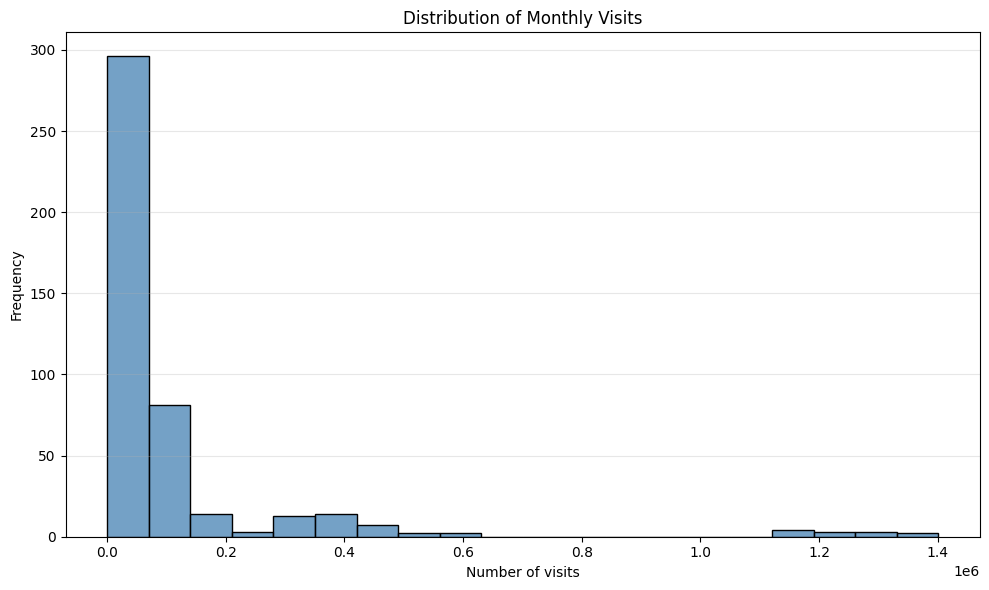

In [9]:
visits = total_visits_by_month["Visits"].dropna()

plt.figure(figsize=(10, 6))
sns.histplot(visits, bins=20, color="steelblue", edgecolor="black")
plt.title("Distribution of Monthly Visits")
plt.xlabel("Number of visits")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

---

##### Data Volatility 

In [10]:
v = total_visits_by_month['Visits']

print(v.quantile(0.25))   # Spread I
print(v.quantile(0.50))   # Spread II
print(v.quantile(0.75))   # Spread III
print(v.max())            # Spread IV
print(v.quantile(0.75) - v.quantile(0.25))   # IQR
print(v.std())            # standard deviation

11659.5
36643.0
92087.75
1401328
80428.25
220664.8136774778


---

##### Data Outliers Graph

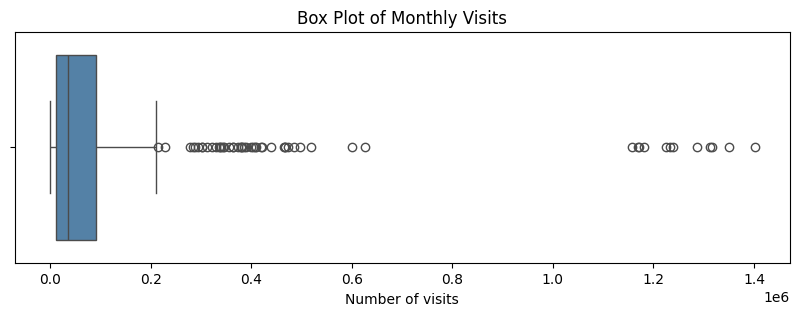

In [11]:
plt.figure(figsize=(10, 3))
sns.boxplot(x=visits, color="steelblue")
plt.title("Box Plot of Monthly Visits")
plt.xlabel("Number of visits")
plt.show()

---

### 2.3 Data investigation

#### Data Covariation

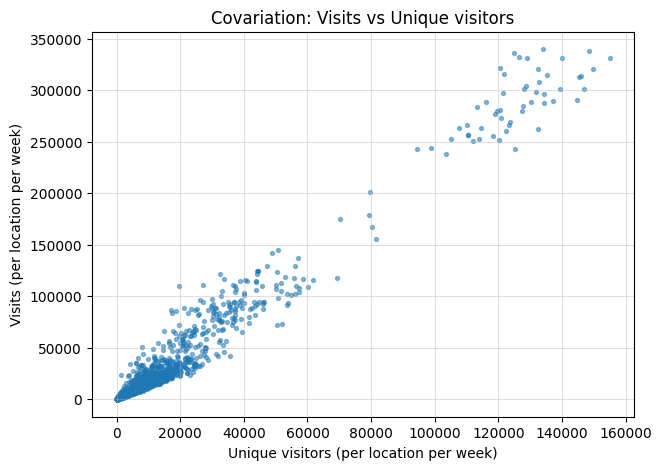

Covariance: 1112630113.46357
Pearson (linearity): 0.9835345839263604
Spearman (monotonicity): 0.9741463887525488


In [12]:
x = total_visits_by_week['Unique']
y = total_visits_by_week['Visits']

plt.figure(figsize=(7, 5))
plt.scatter(x, y, s=8, alpha=0.5)
plt.title('Covariation: Visits vs Unique visitors')
plt.xlabel('Unique visitors (per location per week)')
plt.ylabel('Visits (per location per week)')
plt.grid(True, alpha=0.4)
plt.show()

print('Covariance:', x.cov(y))
print('Pearson (linearity):', x.corr(y))
print('Spearman (monotonicity):', x.corr(y, method='spearman'))

#### Data Correlation